# TourShield - análise exploratória inicial
Helena Gomes | PB TP1 | 25/10/2026
Executável offline a partir da raiz: python eda/eda.py
Recorte CLINC150: 20 intenções ligadas a turismo, reservas, localização e benefícios.
Não é base de fraudes nem de chamados reais. Mensagens originais em inglês.
Todas as seleções, limpezas e estatísticas são feitas com Pandas.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd()
if not (ROOT / "data" / "tourshield.csv").exists():
    ROOT = ROOT.parent  # Notebook opened from eda/.
OUT = ROOT / "reports"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT / "data" / "tourshield.csv", dtype={
    "sample_id": "string", "message": "string", "intent": "string", "split": "string"})
print("Shape original:", df.shape)
print("Tipos:\n", df.dtypes)
print("Describe geral:\n", df.describe(include="all").to_string())
print("Ausentes:\n", df.isna().sum())
print("Duplicatas integrais:", df.duplicated().sum())
print("Duplicatas mensagem/intenção:", df.duplicated(["message", "intent"]).sum())

Shape original: (3000, 4)
Tipos:
 sample_id    string
message      string
intent       string
split        string
dtype: object
Describe geral:
           sample_id                                                   message        intent  split
count          3000                                                      3000          3000   3000
unique         3000                                                      3000            20      3
top     clinc-00700  does ireland have any travel alerts i should be aware of  travel_alert  train
freq              1                                                         1           150   2000
Ausentes:
 sample_id    0
message      0
intent       0
split        0
dtype: int64
Duplicatas integrais: 0
Duplicatas mensagem/intenção: 0


## Decisões de limpeza
1. Não imputar texto nem intenção: remover linha sem esses campos ou com texto vazio.
2. Preservar mensagem original. Criar chave com casefold e espaços uniformizados
   apenas para auditar duplicatas; pontuação, palavras e entidades não são removidas.
3. Remover repetição da mesma chave/intenção. Priorizar test, val, train, nessa ordem,
   evitando que repetição no treino contamine uma futura avaliação. A EDA continua
   descritiva e não seleciona modelo. Não mover amostras entre splits.
4. Se houver mesma chave com rótulos diferentes, exportar e excluir para revisão,
   sem escolher arbitrariamente uma intenção. IDs e split permanecem rastreáveis.
5. Não remover mensagens longas por regra de IQR: podem ser semanticamente válidas.

In [2]:
raw_shape = list(df.shape)
missing = df.isna().sum().to_dict()
exact_dupes = int(df.duplicated().sum())
pair_dupes = int(df.duplicated(["message", "intent"]).sum())
clean = df.dropna(subset=["message", "intent"]).copy()
clean["message"] = clean["message"].str.strip()
clean = clean.loc[clean["message"].ne("") & clean["intent"].str.strip().ne("")].copy()
invalid_removed = len(df) - len(clean)
clean["normalized_key"] = clean["message"].str.casefold().str.replace(r"\s+", " ", regex=True)
conflicting_keys = clean.groupby("normalized_key")["intent"].nunique().loc[lambda s: s.gt(1)].index
conflicts = clean.loc[clean["normalized_key"].isin(conflicting_keys)]
conflicts.to_csv(OUT / "label_conflicts.csv", index=False)
clean = clean.loc[~clean["normalized_key"].isin(conflicting_keys)].copy()
clean["split_priority"] = clean["split"].map({"test": 0, "val": 1, "train": 2})
clean = clean.sort_values(["split_priority", "sample_id"])
duplicates = clean.loc[clean.duplicated(["normalized_key", "intent"], keep="first")]
duplicates.to_csv(OUT / "removed_duplicates.csv", index=False)
clean = clean.drop_duplicates(["normalized_key", "intent"], keep="first").copy()
clean["n_chars"] = clean["message"].str.len()
clean["n_words"] = clean["message"].str.split().str.len()
clean.drop(columns=["normalized_key", "split_priority"]).to_csv(ROOT / "data" / "tourshield_clean.csv", index=False)
print("Shape após limpeza:", clean.shape, "(inclui colunas auxiliares)")
print("Describe numérico:\n", clean[["n_chars", "n_words"]].describe().to_string())
counts = clean["intent"].value_counts().sort_index()
distribution = pd.DataFrame({"original": df["intent"].value_counts(), "clean": counts})
distribution["percent"] = distribution["clean"].div(len(clean)).mul(100)
distribution.to_csv(OUT / "category_distribution.csv")
print("Distribuição:\n", distribution.to_string())
split_counts = pd.crosstab(clean["intent"], clean["split"])
print("Splits após limpeza:\n", split_counts.to_string())
split_counts.to_csv(OUT / "split_distribution.csv")
clean[["n_chars", "n_words"]].describe().to_csv(OUT / "describe.csv")
df.describe(include="all").to_csv(OUT / "describe_original.csv")

Shape após limpeza: (3000, 8) (inclui colunas auxiliares)
Describe numérico:
          n_chars      n_words
count     3000.0  3000.000000
mean   50.085667    10.259333
std    17.368848     3.649363
min          8.0     2.000000
25%         38.0     8.000000
50%         48.0    10.000000
75%         60.0    12.000000
max        136.0    28.000000
Distribuição:
                      original  clean  percent
intent                                       
book_flight               150    150      5.0
book_hotel                150    150      5.0
cancel_reservation        150    150      5.0
car_rental                150    150      5.0
carry_on                  150    150      5.0
confirm_reservation       150    150      5.0
current_location          150    150      5.0
directions                150    150      5.0
distance                  150    150      5.0
flight_status             150    150      5.0
international_visa        150    150      5.0
lost_luggage              150    150   

In [3]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(10, 5))
clean["n_words"].plot.hist(bins=25, ax=ax, color="#16898c", edgecolor="white")
ax.set(title="Comprimento das mensagens", xlabel="Palavras por mensagem (separação por espaços)", ylabel="Número de mensagens")
fig.tight_layout()
fig.savefig(OUT / "figures" / "01_histogram.png", dpi=180)
plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 7))
counts.sort_values().plot.barh(ax=ax, color="#23618a")
ax.set(title="Distribuição das 20 intenções após limpeza", xlabel="Mensagens", ylabel="Intenção")
fig.tight_layout()
fig.savefig(OUT / "figures" / "02_categories.png", dpi=180)
plt.close(fig)
fig, ax = plt.subplots(figsize=(12, 7))
clean.boxplot(column="n_words", by="intent", ax=ax, vert=False, grid=False)
ax.set(title="Comprimento por intenção", xlabel="Palavras por mensagem", ylabel="Intenção")
fig.suptitle("")
fig.tight_layout()
fig.savefig(OUT / "figures" / "03_boxplot.png", dpi=180)
plt.close(fig)

In [4]:
stats = clean.groupby("intent")["n_words"].agg(["count", "mean", "median", "std", "min", "max"])
stats.to_csv(OUT / "length_by_intent.csv")
geo = ["current_location", "directions", "distance", "share_location"]
reservation = ["book_flight", "book_hotel", "cancel_reservation", "confirm_reservation", "car_rental"]
benefits = ["redeem_rewards", "rewards_balance"]
group_stats = pd.DataFrame({
    "grupo": ["geolocalização", "reservas", "benefícios"],
    "n": [int(clean["intent"].isin(g).sum()) for g in [geo, reservation, benefits]],
    "mediana_palavras": [float(clean.loc[clean["intent"].isin(g), "n_words"].median()) for g in [geo, reservation, benefits]]})
group_stats.to_csv(OUT / "group_stats.csv", index=False)
overlap = pd.crosstab(clean["normalized_key"], clean["split"]).gt(0).sum(axis=1).gt(1).sum()
q1, q3 = clean["n_words"].quantile([0.25, 0.75])
summary = {"raw_shape": raw_shape, "clean_rows": len(clean), "clean_export_columns": 6,
           "dtypes": df.dtypes.astype(str).to_dict(), "missing": missing,
           "exact_duplicates": exact_dupes, "pair_duplicates": pair_dupes,
           "invalid_removed": invalid_removed, "normalized_duplicates_removed": len(duplicates),
           "conflicting_rows_removed": len(conflicts), "cross_split_overlap_after": int(overlap),
           "intents": int(clean["intent"].nunique()), "split_counts": clean["split"].value_counts().to_dict(),
           "words": clean["n_words"].describe().to_dict(), "chars": clean["n_chars"].describe().to_dict(),
           "iqr_upper_words": float(q3 + 1.5 * (q3-q1)),
           "long_messages_iqr": int(clean["n_words"].gt(q3 + 1.5 * (q3-q1)).sum()),
           "groups": group_stats.to_dict(orient="records"),
           "shortest_median_intent": str(stats["median"].idxmin()),
           "longest_median_intent": str(stats["median"].idxmax())}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "raw_shape": [
    3000,
    4
  ],
  "clean_rows": 3000,
  "clean_export_columns": 6,
  "dtypes": {
    "sample_id": "string",
    "message": "string",
    "intent": "string",
    "split": "string"
  },
  "missing": {
    "sample_id": 0,
    "message": 0,
    "intent": 0,
    "split": 0
  },
  "exact_duplicates": 0,
  "pair_duplicates": 0,
  "invalid_removed": 0,
  "normalized_duplicates_removed": 0,
  "conflicting_rows_removed": 0,
  "cross_split_overlap_after": 0,
  "intents": 20,
  "split_counts": {
    "train": 2000,
    "test": 600,
    "val": 400
  },
  "words": {
    "count": 3000.0,
    "mean": 10.259333333333334,
    "std": 3.649363255822382,
    "min": 2.0,
    "25%": 8.0,
    "50%": 10.0,
    "75%": 12.0,
    "max": 28.0
  },
  "chars": {
    "count": 3000.0,
    "mean": 50.08566666666667,
    "std": 17.36884817284015,
    "min": 8.0,
    "25%": 38.0,
    "50%": 48.0,
    "75%": 60.0,
    "max": 136.0
  },
  "iqr_upper_words": 18.0,
  "long_messages_iqr": 98,
  "groups"

## Hipóteses exploratórias (não são conclusões causais)
H1. A quase uniformidade das categorias decorre da construção balanceada do benchmark;
    a frequência de intenções em produção deve diferir. Testar com chamados reais por período.
H2. Mensagens de reservas podem exigir mais contexto que consultas de localização.
    Comparar medianas em group_stats.csv e dispersões no boxplot; validar em amostra externa
    com intervalo de confiança por bootstrap e teste não paramétrico predefinido.
H3. Comprimento semelhante entre rewards_balance e redeem_rewards pode tornar comprimento
    insuficiente para distinguir consulta de saldo de solicitação de resgate. Futuramente,
    comparar baseline de comprimento com representação textual, usando macro-F1 e matriz
    de confusão nos splits preservados. Isso não demonstra fraude.
Mensagens em inglês, crowdsourcing, intenção única e recorte deliberado limitam validade
externa. Sem GPS, transações ou rótulos de fraude, não é possível testar spoofing ou abuso.

## Gráficos gerados
Fonte: recorte CLINC150, elaboração própria com Pandas/Matplotlib.

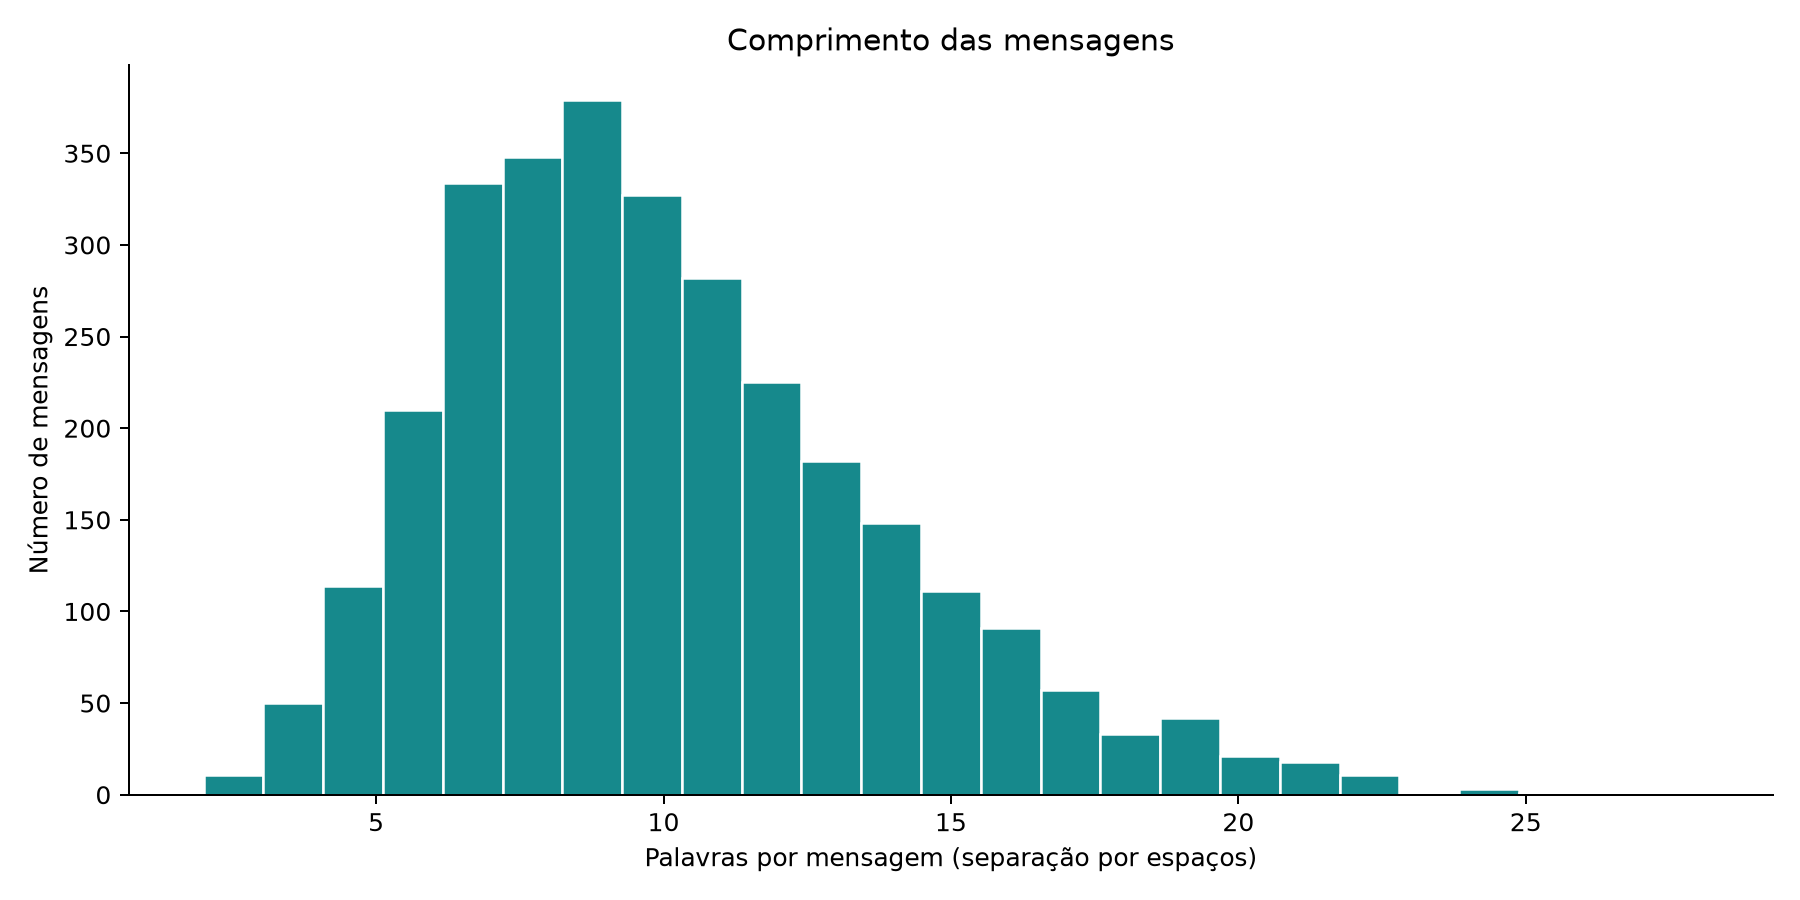

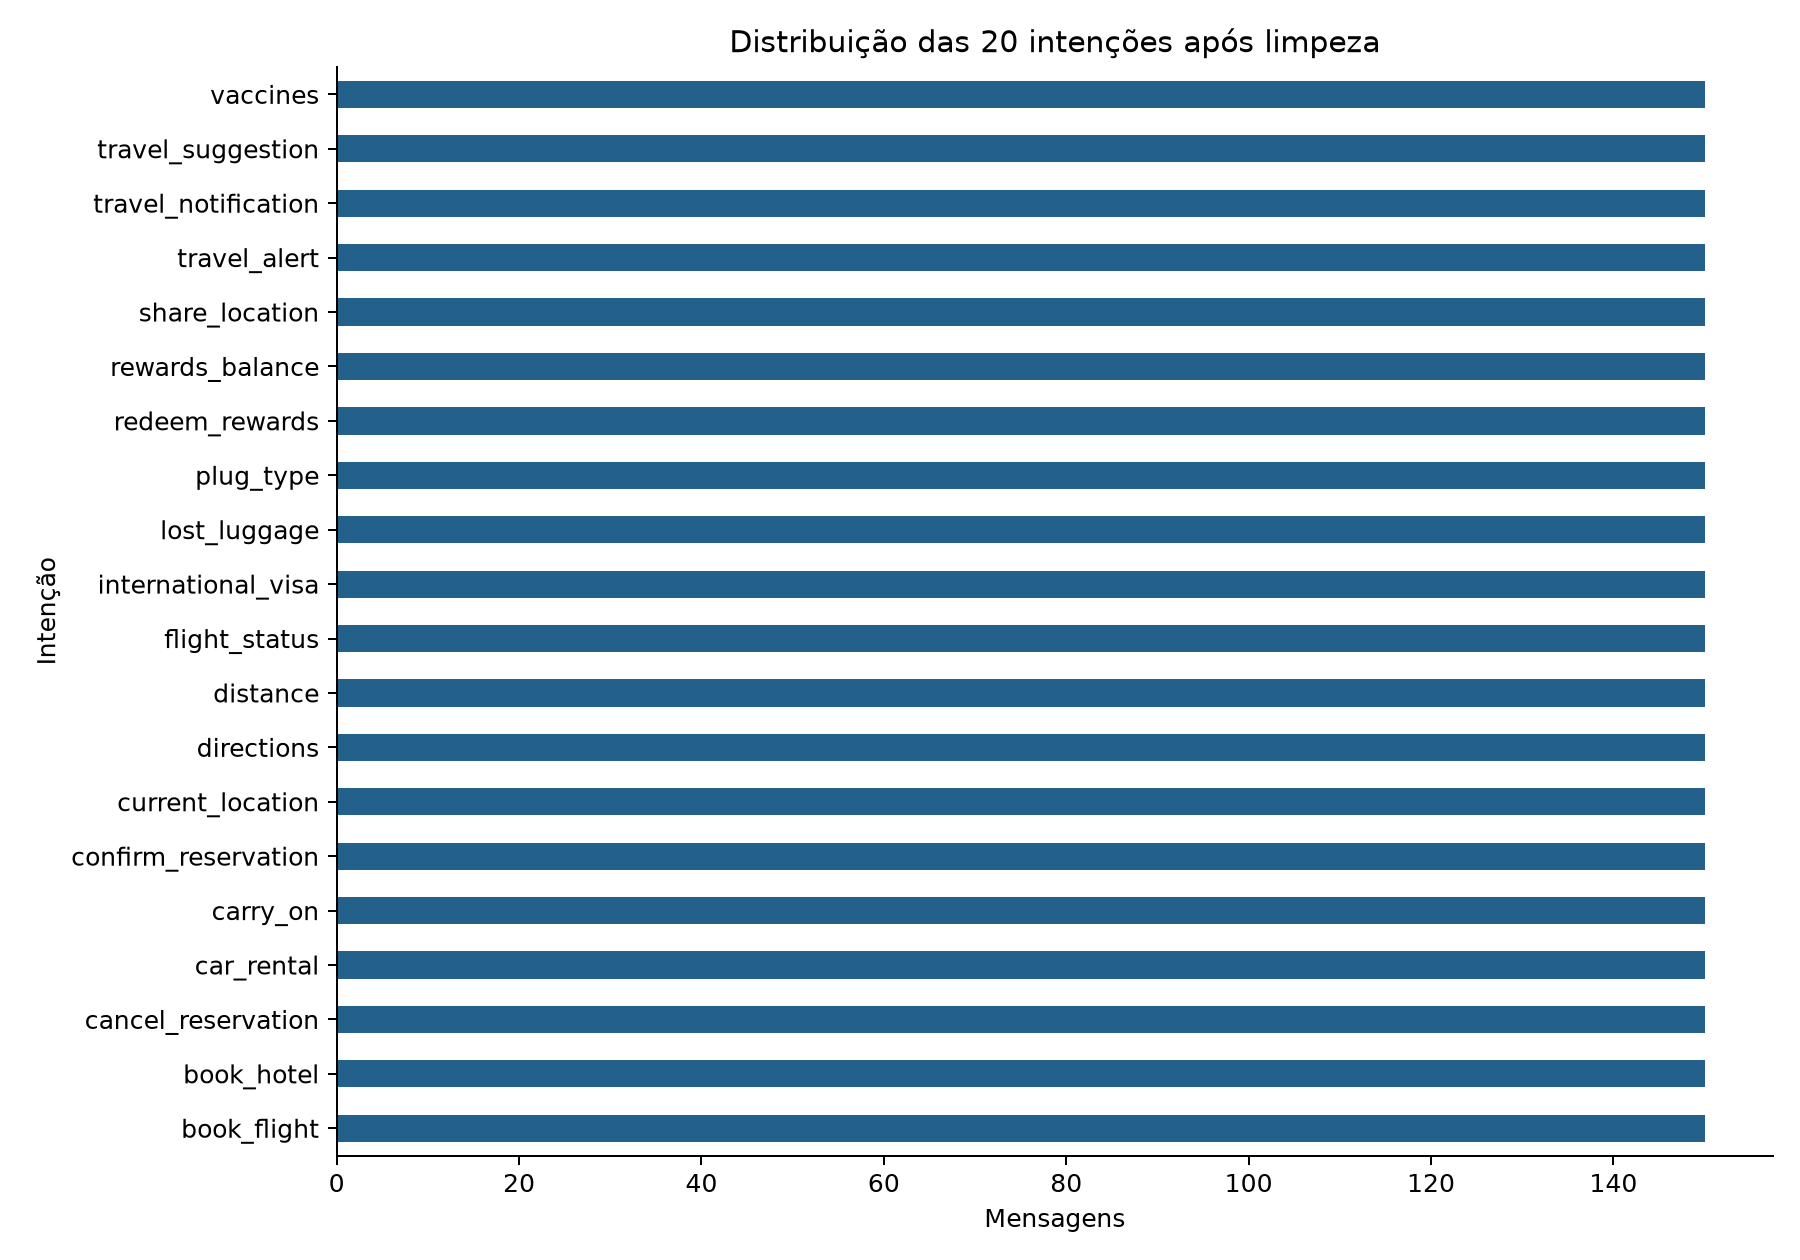

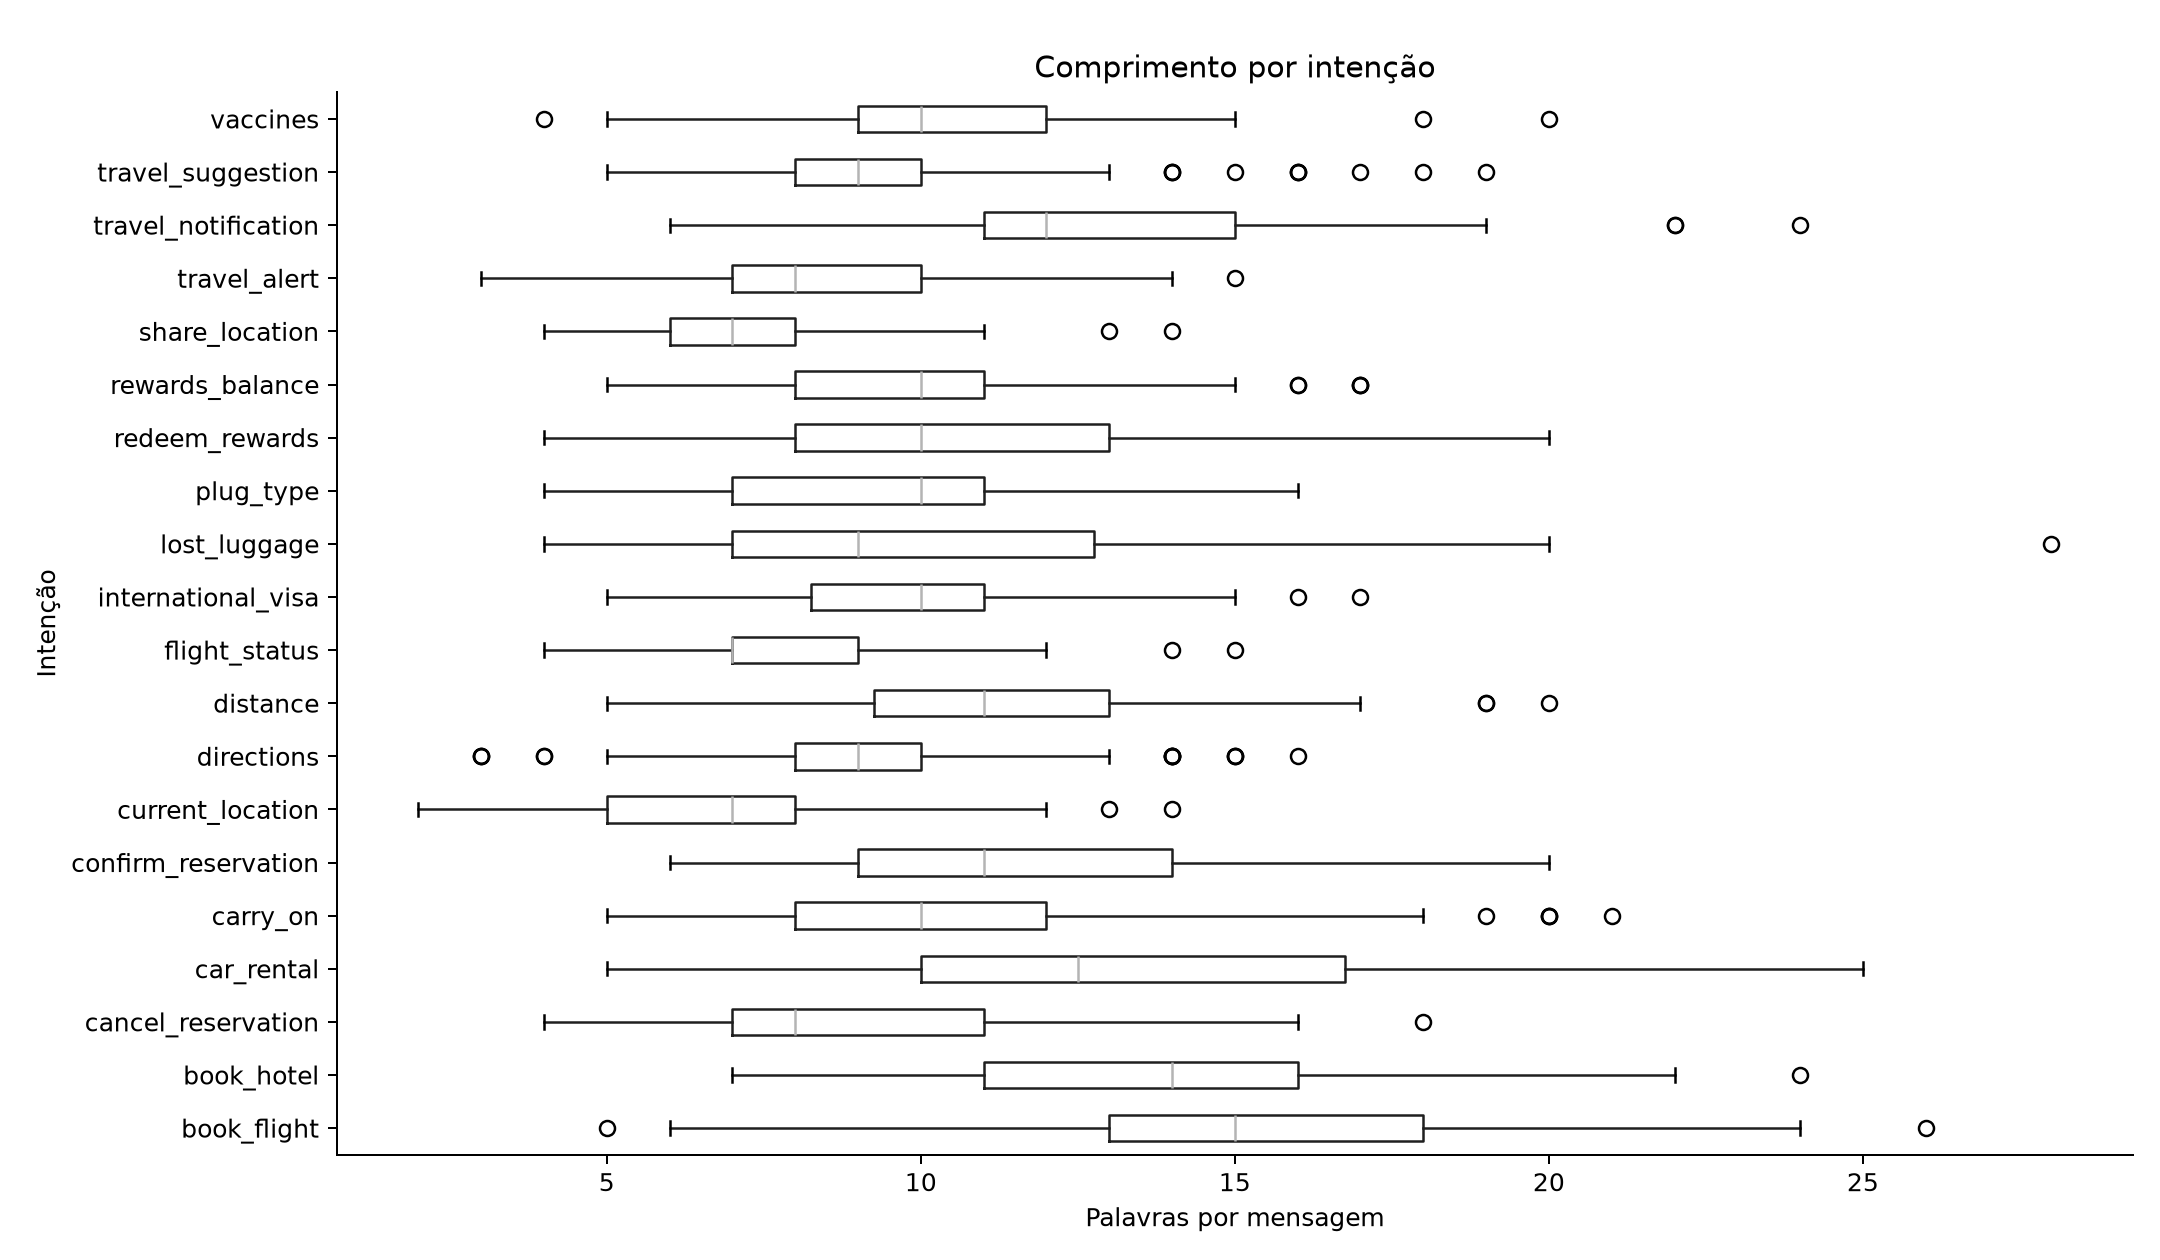

In [5]:
from IPython.display import Image, display
for name in ["01_histogram.png", "02_categories.png", "03_boxplot.png"]:
    display(Image(filename=str(OUT / "figures" / name)))